# Limpieza unificada - Shark Attack (GSAF)

Este cuaderno junta en un solo flujo las limpiezas de los cinco cuadernos originales
(`Injury` y `Species`, `Location`, `Activity` y `Fatal Y/N`, `Country` y `State`, y
`Activity` / `Country` / `Sex` / `Age` / `Year` del cuaderno `shark-attack`) y termina con
**gráficas de antes y después**.

## Reglas comunes (se aplican igual a todas las columnas de texto)

| # | Regla | Cómo |
|---|-------|------|
| 1 | Nulos -> `Unknown` | NaN, vacíos y marcadores como `?`, `n/a`, `none`, `unknown`... pasan a `Unknown` |
| 2 | `strip()` | Se quitan espacios al inicio/final y los espacios repetidos |
| 3 | Primera mayúscula, resto minúscula | `str.capitalize()` |

Además, cada columna conserva su limpieza específica (paréntesis y `?` en `Injury`/`Species`/`Location`,
typos de `Activity`, países y estados con nombres distintos, `Sex` solo M/F, etc.).

**Excepción:** `Age` y `Year` son numéricas. Sus nulos se quedan como `<NA>` porque un `"Unknown"`
las convertiría otra vez en texto.

## 1. Librerías y carga del dataset

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
# Cambia la ruta si el archivo no está junto al cuaderno
df_raw = pd.read_excel("GSAF5.xls")
df_raw.shape

(7125, 23)

## 2. Funciones comunes (las 3 reglas)

In [3]:
UNKNOWN = "Unknown"

# Textos que equivalen a "no hay dato" (se comparan en minúsculas, ya sin espacios)
MARCADORES_NULOS = {"", "?", "unknown", "unk", "n/a", "na", "nan", "none", "null",
                    "not known", "not reported"}

# Marcadores extra que solo se usan en Injury y Species
MARCADORES_EXTRA = {"not stated", "not specified", "undetermined", "unidentified", "no details"}


def limpiar_espacios(serie):
    """Texto de pandas (admite nulos), sin espacios al inicio/final ni espacios repetidos."""
    return (
        serie.astype("string")
        .str.normalize("NFKC")                  # p. ej. espacio duro -> espacio normal
        .str.replace(r"\s+", " ", regex=True)   # varios espacios -> uno
        .str.strip()                            # REGLA 2: strip()
    )


def normalizar_texto(serie, correcciones=None, marcadores=MARCADORES_NULOS, signos=""):
    """Aplica las 3 reglas comunes a una columna de texto.

    correcciones : dict {texto_en_minusculas: texto_correcto_en_minusculas}
    marcadores   : textos (en minúsculas) que se consideran nulos
    signos       : signos extra que se quitan de los extremos (p. ej. " .;,")
    """
    s = limpiar_espacios(serie)
    if signos:
        s = s.str.strip(signos + " ")
    s = s.str.lower()
    if correcciones:
        s = s.replace(correcciones)
    s = s.mask(s.isin(marcadores))              # marcadores -> nulo
    s = s.str.capitalize()                      # REGLA 3: Primera mayúscula, resto minúscula
    return s.fillna(UNKNOWN)                    # REGLA 1: nulos -> Unknown

## 3. Limpieza específica de cada columna

### 3.1 `Fatal Y/N` (de `limpieza_activity_fatal`)

In [4]:
FATAL_VALIDOS = ["Y", "N"]
INJURY_EVIDENCE = r"\b(?:fatal|died|death|drown\w*|remains|body washed|scaveng\w*)\b"

REASON_MISSING = "Ausente o desconocido"
REASON_INVALID = "Valor no valido; verificar fuente primaria"
REASON_EVIDENCE = "; muerte/restos mencionados: verificar causa y participacion del tiburon"
REASON_CONFLICT = "Posible contradiccion N / FATAL; conservar N hasta verificar fuente"


def limpiar_fatal(df):
    """Fatal Y/N -> Y / N / Unknown, y anota en 'Fatal_review_reason' los casos a revisar a mano.
    Nunca deduce N a partir de lesiones ni Y a partir de restos humanos.
    IMPORTANTE: se ejecuta ANTES que limpiar_injury, porque lee el texto original de Injury."""
    df = df.copy()
    fatal = limpiar_espacios(df["Fatal Y/N"]).str.upper()
    injury = limpiar_espacios(df["Injury"])

    limpio = fatal.where(fatal.isin(FATAL_VALIDOS), UNKNOWN)
    desconocido = limpio.eq(UNKNOWN)
    ausente = fatal.isna() | fatal.str.lower().isin(MARCADORES_NULOS)
    evidencia = injury.str.contains(INJURY_EVIDENCE, case=False, na=False)
    conflicto = limpio.eq("N") & injury.str.contains(r"^\s*FATAL\b", case=False, na=False)

    motivo = pd.Series("", index=df.index, dtype="object")
    motivo[desconocido & ausente] = REASON_MISSING
    motivo[desconocido & ~ausente] = REASON_INVALID
    motivo[desconocido & evidencia] += REASON_EVIDENCE
    motivo[conflicto] = REASON_CONFLICT

    df["Fatal Y/N"] = limpio.astype("string")
    df["Fatal_review_reason"] = motivo
    return df

### 3.2 `Injury` y `Species` (de `limpieza_injury_species`)

In [5]:
def quitar_ruido(serie):
    """Quita lo que va entre paréntesis (con los paréntesis), '?' y comillas."""
    s = serie.astype("string")
    s = s.str.replace(r"\(.*?\)", "", regex=True)
    s = s.str.replace(r'[?"“”]', "", regex=True)
    return s


def limpiar_injury(df):
    df = df.copy()
    df["Injury"] = normalizar_texto(quitar_ruido(df["Injury"]),
                                    marcadores=MARCADORES_NULOS | MARCADORES_EXTRA, signos=" .;,")
    return df


# Registros de Species que no indican una especie real
PAT_SPECIES_DUDOSA = r"(?i)(involvement|involment|invovlement|questionable|invalid|unconfirmed|not confirmed)"
# Solo tamaño sin especie: "6' shark", "1.8 m [6'] shark", "A small shark"
PAT_SPECIES_SOLO_TAMANO = (r"(?i)^(?:[\d.\s\[\]'/-]|\b(?:m|ft|feet|to|a|an|the|small|large|big|juvenile)\b)*sharks?$")


def limpiar_species(df):
    df = df.copy()
    columna = "Species " if "Species " in df.columns else "Species"   # en el Excel lleva un espacio al final
    s = normalizar_texto(quitar_ruido(df[columna]),
                         marcadores=MARCADORES_NULOS | MARCADORES_EXTRA, signos=" .;,")
    s = s.mask(s.str.contains(PAT_SPECIES_DUDOSA, regex=True, na=False), UNKNOWN)
    s = s.mask(s.str.contains(PAT_SPECIES_SOLO_TAMANO, regex=True, na=False), UNKNOWN)
    df[columna] = s
    return df

### 3.3 `Location` (de `limpieza_location`)

El cuaderno original corregía a mano la capitalización de 6 ubicaciones (`Cheynes beach` -> `Cheynes Beach`...).
Con la regla 3 (primera mayúscula y el resto minúscula) esas correcciones dejan de tener sentido, así que se han quitado.

In [6]:
def limpiar_location(df):
    df = df.copy()
    s = (
        df["Location"].astype("string")
        .str.replace(r"\([^)]*\)?", "", regex=True)   # quita paréntesis y su contenido
        .str.replace("?", "", regex=False)
        .str.replace(r"\s+,", ",", regex=True)         # "Perth , WA" -> "Perth, WA"
    )
    df["Location"] = normalizar_texto(s)
    return df

### 3.4 `Activity` (de `shark-attack` y `limpieza_activity_fatal`)

In [7]:
ACTIVITY_CORRECTIONS = {
    "swimmingq": "swimming",
    "spearfishiong": "spearfishing",
    "snorkelling": "snorkeling",
    "boggie boarding": "boogie boarding",
}


def limpiar_activity(df):
    df = df.copy()
    df["Activity"] = normalizar_texto(df["Activity"], correcciones=ACTIVITY_CORRECTIONS)
    return df

### 3.5 `Country` y `State` (de `limpieza_country_state`)

In [8]:
COUNTRY_CORRECTIONS = {
    "columbia": "colombia",
    "ceylon": "sri lanka",
    "ceylon (sri lanka)": "sri lanka",
    "maldive islands": "maldives",
    "reunion island": "reunion",
}
STATE_CORRECTIONS = {"nsw": "new south wales"}

# Valores de Country que parecen un océano, un mar o varios países (no un país concreto)
PAT_COUNTRY_REVISAR = r"\b(?:ocean|sea|between|coast of|africa|asia|balkans)\b|/"


def limpiar_country(df):
    df = df.copy()
    df["Country"] = normalizar_texto(df["Country"], correcciones=COUNTRY_CORRECTIONS)
    # Se marca para revisar, salvo "South africa", que es un país válido
    df["Country_needs_review"] = (
        df["Country"].str.contains(PAT_COUNTRY_REVISAR, case=False, regex=True, na=False)
        & df["Country"].ne("South africa")
    )
    return df


def limpiar_state(df):
    df = df.copy()
    df["State"] = normalizar_texto(df["State"], correcciones=STATE_CORRECTIONS)
    return df

### 3.6 `Sex`, `Age` y `Year` (de `shark-attack`)

In [9]:
def limpiar_sex(df):
    """Solo M, F o Unknown."""
    df = df.copy()
    s = normalizar_texto(df["Sex"], correcciones={"m x 2": "m"})
    df["Sex"] = s.where(s.isin(["M", "F"]), UNKNOWN)
    return df


def limpiar_columna_numerica(df, columna, minimo=None, maximo=None, entero=False):
    """Extrae el número del texto, descarta lo que no sea número o esté fuera de rango.
    Los nulos se quedan como <NA> (la columna sigue siendo numérica)."""
    df = df.copy()
    serie = df[columna]
    if serie.dtype == "object":
        serie = serie.astype(str).str.extract(r"(-?\d+\.?\d*)")[0]   # "20s" -> 20, "teen" -> NaN
    serie = pd.to_numeric(serie, errors="coerce")
    if minimo is not None:
        serie = serie.where(serie >= minimo)
    if maximo is not None:
        serie = serie.where(serie <= maximo)
    if entero:
        serie = serie.round().astype("Int64")
    df[columna] = serie
    return df

## 4. Aplicar toda la limpieza

In [10]:
df = df_raw.copy()                                   # siempre se parte del original

df = limpiar_fatal(df)                               # antes que Injury (usa su texto original)
df = limpiar_injury(df)
df = limpiar_species(df)
df = limpiar_location(df)
df = limpiar_activity(df)
df = limpiar_country(df)
df = limpiar_state(df)
df = limpiar_sex(df)
df = limpiar_columna_numerica(df, "Age", minimo=1, maximo=100, entero=True)
df = limpiar_columna_numerica(df, "Year", entero=True)

# Copias de los valores originales (como en limpieza_country_state)
df["Country_original"] = df_raw["Country"]
df["State_original"] = df_raw["State"]

df.shape

/tmp/ipykernel_450/308627509.py:27: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  s = s.mask(s.str.contains(PAT_SPECIES_DUDOSA, regex=True, na=False), UNKNOWN)


(7125, 27)

## 5. Comprobaciones

In [11]:
COLS_TEXTO = ["Country", "State", "Location", "Activity", "Sex", "Fatal Y/N", "Injury", "Species "]
COLS_NUM = ["Age", "Year"]
COLS_NUEVAS = ["Fatal_review_reason", "Country_needs_review", "Country_original", "State_original"]


def validar(original, limpio):
    # --- Estructura ---
    assert len(limpio) == len(original), "Cambió el número de filas"
    assert limpio.index.equals(original.index), "Cambió el índice"
    intactas = [c for c in original.columns if c not in COLS_TEXTO + COLS_NUM]
    assert limpio[intactas].equals(original[intactas]), "Se modificó una columna que no tocaba"

    # --- Las 3 reglas en todas las columnas de texto ---
    for c in COLS_TEXTO:
        s = limpio[c]
        assert s.notna().all(), f"{c}: quedan nulos (deberían ser 'Unknown')"
        assert (s == s.str.strip()).all(), f"{c}: quedan espacios al inicio/final"
        assert (s == s.str.capitalize()).all(), f"{c}: hay valores que no son 'Primera mayúscula, resto minúscula'"
        assert (s.str.lower().isin({m for m in MARCADORES_NULOS if m} - {"unknown"})).sum() == 0, \
            f"{c}: quedan marcadores de nulo sin convertir"

    # --- Dominios cerrados ---
    assert set(limpio["Fatal Y/N"]) <= {"Y", "N", UNKNOWN}, "Dominio de Fatal Y/N incorrecto"
    assert set(limpio["Sex"]) <= {"M", "F", UNKNOWN}, "Dominio de Sex incorrecto"

    # --- Un Y/N válido del original nunca cambia ---
    orig = limpiar_espacios(original["Fatal Y/N"]).str.upper()
    valido = orig.isin(FATAL_VALIDOS)
    assert (limpio.loc[valido, "Fatal Y/N"] == orig[valido]).all(), "Se cambió un Y/N válido"

    # --- Fatal_review_reason ---
    motivo = limpio["Fatal_review_reason"]
    assert (motivo[limpio["Fatal Y/N"].eq(UNKNOWN)] != "").all(), "Hay Unknown sin motivo de revisión"
    assert limpio.loc[motivo.ne(""), "Fatal Y/N"].isin([UNKNOWN, "N"]).all(), "Hay una Y marcada para revisión"

    # --- Numéricas ---
    assert str(limpio["Age"].dtype) == "Int64" and limpio["Age"].dropna().between(1, 100).all()
    assert str(limpio["Year"].dtype) == "Int64"

    print("Validación OK: las 3 reglas se cumplen en", len(COLS_TEXTO), "columnas de texto")


validar(df_raw, df)

print("\nFatal Y/N:");  print(df["Fatal Y/N"].value_counts().to_string())
print("\nSex:");        print(df["Sex"].value_counts().to_string())
print("\nCasos de Fatal Y/N a revisar a mano:", df["Fatal_review_reason"].ne("").sum())
print("Country marcados para revisar (océanos, mares, varios países):", int(df["Country_needs_review"].sum()))

Validación OK: las 3 reglas se cumplen en 8 columnas de texto

Fatal Y/N:
Fatal Y/N
N          4986
Y          1496
Unknown     643

Sex:
Sex
M          5720
F           820
Unknown     585

Casos de Fatal Y/N a revisar a mano: 644
Country marcados para revisar (océanos, mares, varios países): 109


## 6. Gráficas de los cambios

Primero se calculan las métricas de antes (`df_raw`) y después (`df`) y luego se dibujan.

In [12]:
# --- Estilo común de las gráficas ---
C_ANTES, C_DESPUES = "#eb6834", "#2a78d6"      # antes = naranja, después = azul
C_NULO, C_CORREGIDO = "#1baf7a", "#6250d6"     # para la gráfica de filas modificadas
INK, INK_SUAVE, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": INK_SUAVE, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_SUAVE, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})

nombre = lambda c: c.strip()     # "Species " -> "Species"
TODAS = COLS_TEXTO + COLS_NUM


def es_nulo_o_unknown(serie):
    return serie.isna() | serie.astype("string").eq(UNKNOWN)


def en_formato(serie):
    """% de valores no nulos que ya cumplen strip() + primera mayúscula/resto minúscula."""
    s = serie.dropna().astype("string")
    return 100 * ((s == s.str.strip()) & (s == s.str.capitalize())).mean()


def valor_cambiado(antes, despues, numerica):
    if numerica:
        # Antes, la columna puede tener texto ("20s"): se compara como número (float) para no depender de <NA>
        a = pd.to_numeric(antes, errors="coerce").astype("float64")
        d = pd.to_numeric(despues, errors="coerce").astype("float64")
        return ~((a == d) | (a.isna() & d.isna()))
    a = antes.astype("string").fillna("<NA>")
    d = despues.astype("string").fillna("<NA>")
    return a != d


filas = []
for c in TODAS:
    num = c in COLS_NUM
    antes, despues = df_raw[c], df[c]
    cambiada = valor_cambiado(antes, despues, num)
    nulo_a_unknown = cambiada & antes.isna()
    filas.append({
        "columna": nombre(c),
        "nulos_antes": int(antes.isna().sum()),
        "nulos_o_unknown_despues": int(despues.isna().sum() if num else (despues == UNKNOWN).sum()),
        "unicos_antes": int(antes.nunique()),
        "unicos_despues": int(despues.nunique()),
        "filas_cambiadas": int(cambiada.sum()),
        "nulo_a_unknown": int(nulo_a_unknown.sum()),
        "valor_corregido": int((cambiada & ~nulo_a_unknown).sum()),
        "formato_ok_antes_%": None if num else round(en_formato(antes), 1),
        "formato_ok_despues_%": None if num else round(en_formato(despues), 1),
    })

resumen = pd.DataFrame(filas).set_index("columna")
resumen["unicos_reduccion_%"] = (100 * (1 - resumen["unicos_despues"] / resumen["unicos_antes"])).round(1)
resumen["filas_cambiadas_%"] = (100 * resumen["filas_cambiadas"] / len(df)).round(1)
resumen

,nulos_antes,nulos_o_unknown_despues,unicos_antes,unicos_despues,filas_cambiadas,nulo_a_unknown,valor_corregido,formato_ok_antes_%,formato_ok_despues_%,unicos_reduccion_%,filas_cambiadas_%
columna,,,,,,,,,,,
Country,50,50,257,210,7019,50,6969,1.5,100.0,18.3,98.5
State,487,488,956,917,3997,487,3510,47.2,100.0,4.1,56.1
Location,567,570,4662,4570,6190,567,5623,14.3,100.0,2.0,86.9
Activity,583,590,1617,1549,1331,583,748,89.0,100.0,4.2,18.7
Sex,578,585,12,3,598,578,20,99.8,100.0,75.0,8.4
Fatal Y/N,561,643,12,3,653,561,92,98.8,100.0,75.0,9.2
Injury,36,86,4229,4083,2789,36,2753,64.3,100.0,3.5,39.1
Species,3131,4592,1772,1350,5451,3131,2320,81.2,100.0,23.8,76.5
Age,2994,3069,252,83,104,0,104,NaN,NaN,67.1,1.5


### 6.1 ¿Cuántos valores cumplen ya el formato (strip + primera mayúscula)?

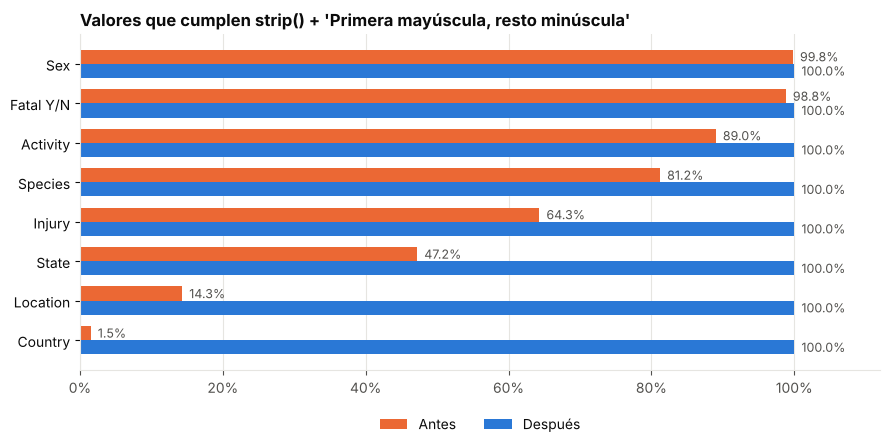

In [13]:
d = resumen.dropna(subset=["formato_ok_antes_%"]).sort_values("formato_ok_antes_%", ascending=False)
y = np.arange(len(d))
h = 0.36

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(y - h/2, d["formato_ok_antes_%"], h, color=C_ANTES, label="Antes")
ax.barh(y + h/2, d["formato_ok_despues_%"], h, color=C_DESPUES, label="Después")
for yi, a, b in zip(y, d["formato_ok_antes_%"], d["formato_ok_despues_%"]):
    ax.text(a + 1, yi - h/2, f"{a:.1f}%", va="center", fontsize=9, color=INK_SUAVE)
    ax.text(b + 1, yi + h/2, f"{b:.1f}%", va="center", fontsize=9, color=INK_SUAVE)
ax.set_yticks(y, d.index)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("Valores que cumplen strip() + 'Primera mayúscula, resto minúscula'")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.show()

### 6.2 Nulos antes vs. `Unknown` después

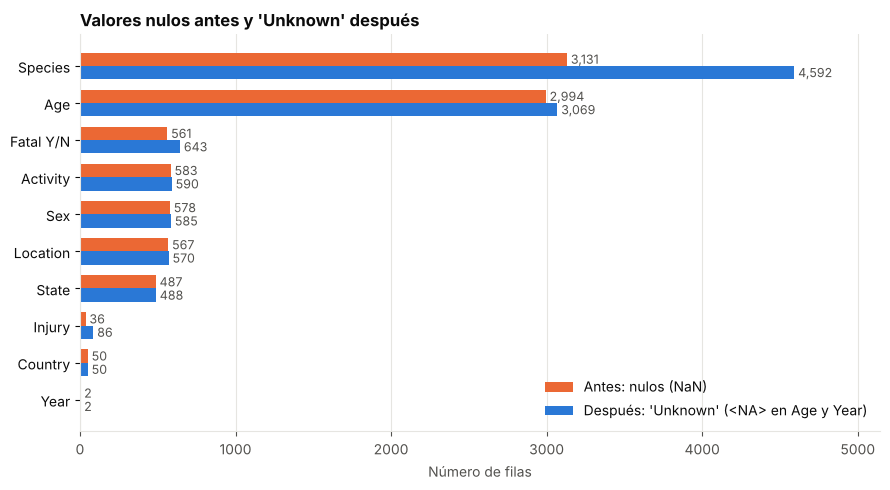

In [14]:
d = resumen.sort_values("nulos_o_unknown_despues", ascending=False)
y = np.arange(len(d))
h = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y - h/2, d["nulos_antes"], h, color=C_ANTES, label="Antes: nulos (NaN)")
ax.barh(y + h/2, d["nulos_o_unknown_despues"], h, color=C_DESPUES, label="Después: 'Unknown' (<NA> en Age y Year)")
for yi, a, b in zip(y, d["nulos_antes"], d["nulos_o_unknown_despues"]):
    ax.text(a + 25, yi - h/2, f"{a:,}", va="center", fontsize=9, color=INK_SUAVE)
    ax.text(b + 25, yi + h/2, f"{b:,}", va="center", fontsize=9, color=INK_SUAVE)
ax.set_yticks(y, d.index)
ax.invert_yaxis()
ax.set_xlim(0, d[["nulos_antes", "nulos_o_unknown_despues"]].max().max() * 1.12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Número de filas")
ax.set_title("Valores nulos antes y 'Unknown' después")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

> Si "después" supera a "antes", es porque además de los nulos reales se han convertido a `Unknown`
> los marcadores (`?`, `n/a`...), los valores inválidos (`Sex`, `Fatal Y/N`) o las especies que no indican especie.

### 6.3 Reducción de valores distintos (variantes unificadas)

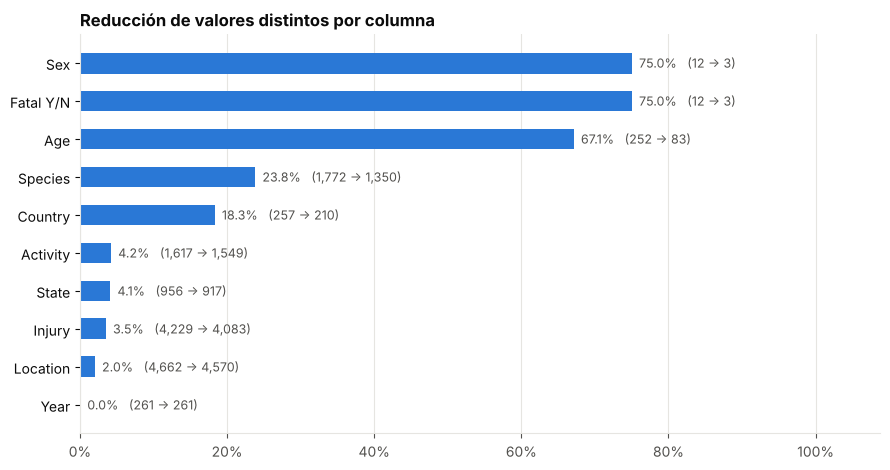

In [15]:
d = resumen.sort_values("unicos_reduccion_%", ascending=False)
y = np.arange(len(d))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(y, d["unicos_reduccion_%"], 0.55, color=C_DESPUES)
for yi, (_, r) in zip(y, d.iterrows()):
    ax.text(max(r["unicos_reduccion_%"], 0) + 1, yi,
            f"{r['unicos_reduccion_%']:.1f}%   ({int(r['unicos_antes']):,} -> {int(r['unicos_despues']):,})",
            va="center", fontsize=9, color=INK_SUAVE)
ax.set_yticks(y, d.index)
ax.invert_yaxis()
ax.set_xlim(0, d["unicos_reduccion_%"].max() * 1.45)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("Reducción de valores distintos por columna")
plt.tight_layout()
plt.show()

### 6.4 Filas modificadas por columna

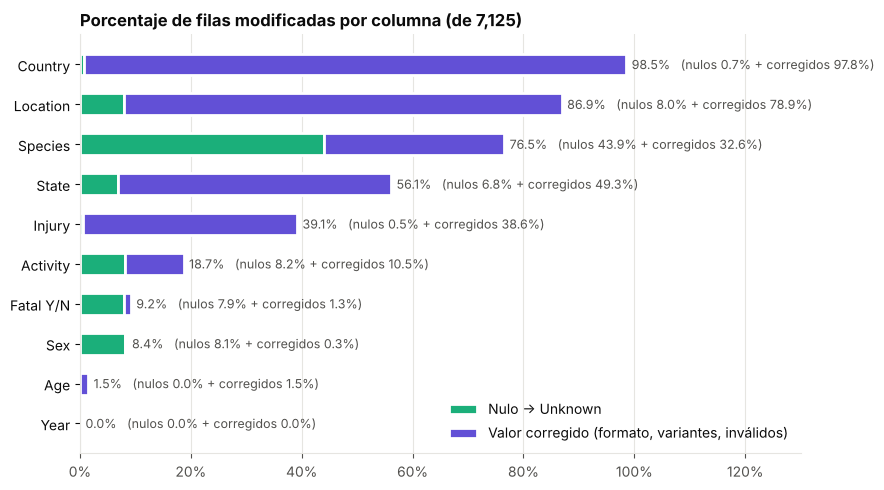

In [16]:
d = resumen.sort_values("filas_cambiadas", ascending=False)
n = len(df)
y = np.arange(len(d))
p_nulo = 100 * d["nulo_a_unknown"] / n
p_corr = 100 * d["valor_corregido"] / n

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y, p_nulo, 0.55, color=C_NULO, edgecolor="white", linewidth=2, label="Nulo -> Unknown")
ax.barh(y, p_corr, 0.55, left=p_nulo, color=C_CORREGIDO, edgecolor="white", linewidth=2,
        label="Valor corregido (formato, variantes, inválidos)")
for yi, a, b in zip(y, p_nulo, p_corr):
    ax.text(a + b + 1, yi, f"{a + b:.1f}%   (nulos {a:.1f}% + corregidos {b:.1f}%)",
            va="center", fontsize=9, color=INK_SUAVE)
ax.set_yticks(y, d.index)
ax.invert_yaxis()
ax.set_xlim(0, 130)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title(f"Porcentaje de filas modificadas por columna (de {n:,})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.5 Distribución de `Fatal Y/N` y `Sex`: antes y después

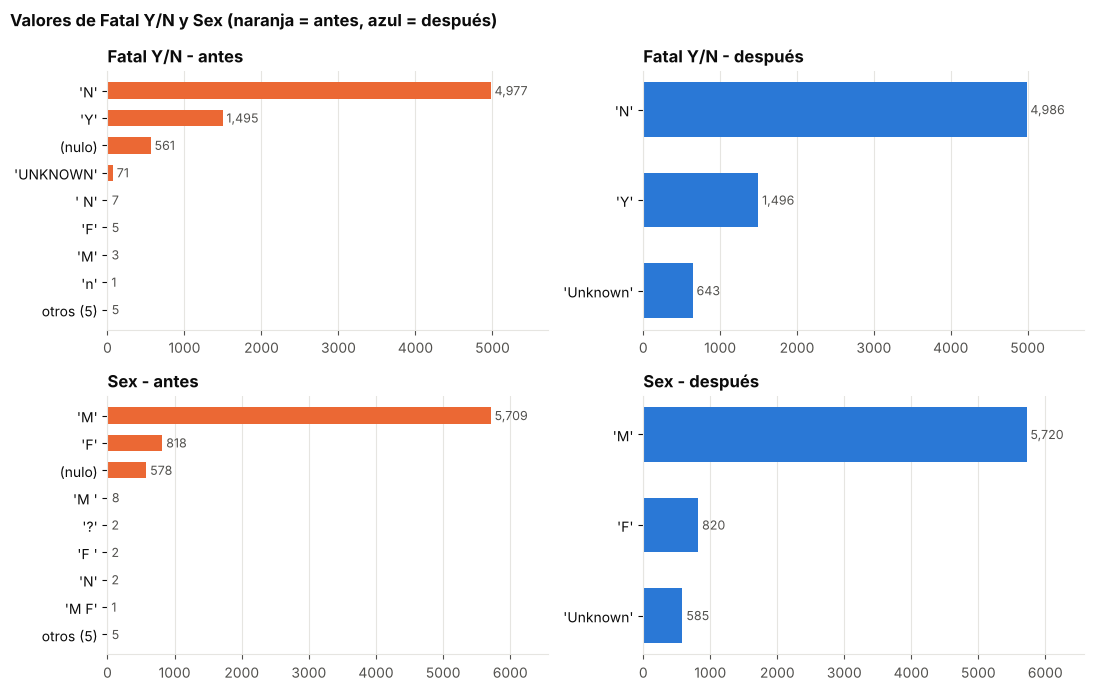

In [17]:
def etiqueta(v):
    return "(nulo)" if pd.isna(v) else f"'{v}'"


def barras_distribucion(ax, serie, color, titulo, top=8):
    vc = serie.astype("string").value_counts(dropna=False)
    otros = vc.iloc[top:].sum()
    vc = vc.iloc[:top]
    etiquetas = [etiqueta(v) for v in vc.index] + ([f"otros ({len(serie.astype('string').value_counts(dropna=False)) - top})"] if otros else [])
    valores = list(vc.values) + ([otros] if otros else [])
    y = np.arange(len(valores))
    ax.barh(y, valores, 0.6, color=color)
    for yi, v in zip(y, valores):
        ax.text(v + max(valores) * 0.01, yi, f"{v:,}", va="center", fontsize=9, color=INK_SUAVE)
    ax.set_yticks(y, etiquetas)
    ax.invert_yaxis()
    ax.set_xlim(0, max(valores) * 1.15)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
barras_distribucion(axes[0, 0], df_raw["Fatal Y/N"], C_ANTES,   "Fatal Y/N - antes")
barras_distribucion(axes[0, 1], df["Fatal Y/N"],     C_DESPUES, "Fatal Y/N - después")
barras_distribucion(axes[1, 0], df_raw["Sex"],       C_ANTES,   "Sex - antes")
barras_distribucion(axes[1, 1], df["Sex"],           C_DESPUES, "Sex - después")
fig.suptitle("Valores de Fatal Y/N y Sex (naranja = antes, azul = después)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 6.6 Top 10 de `Country` y `Activity`: antes y después

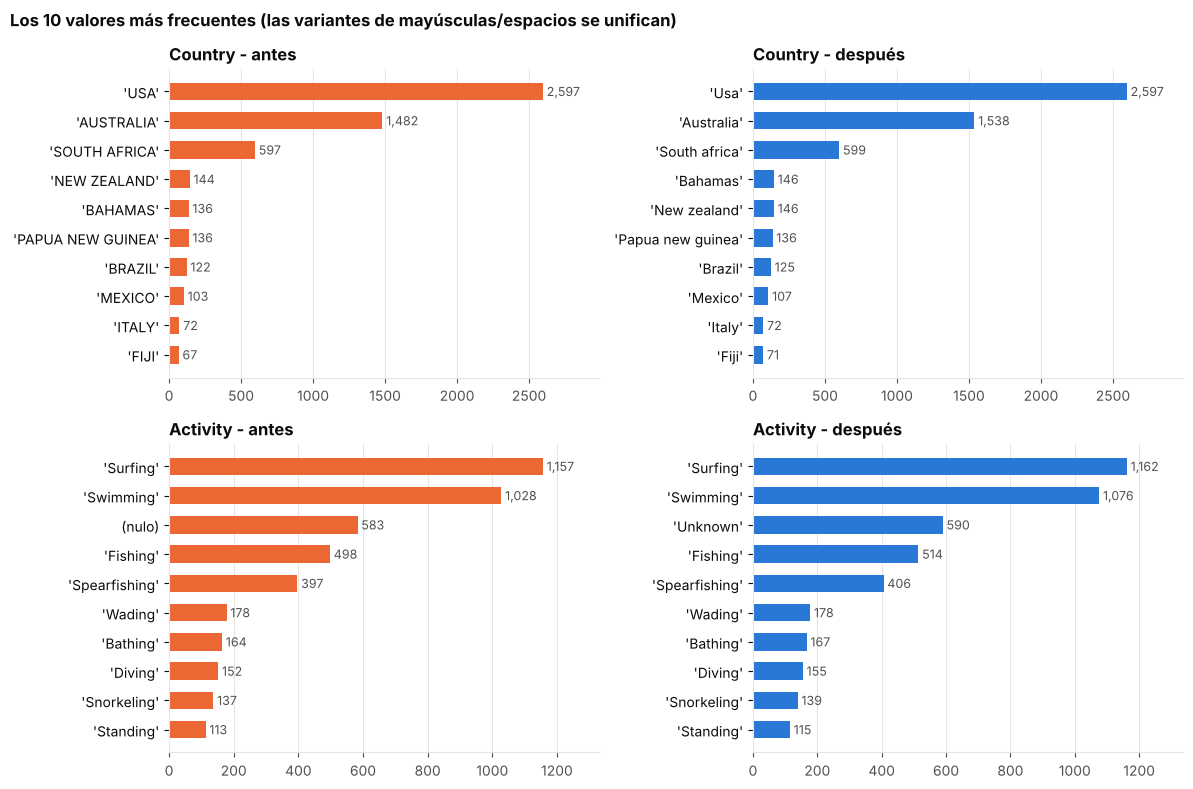

In [18]:
def top10(ax, serie, color, titulo):
    vc = serie.astype("string").value_counts(dropna=False).head(10)
    y = np.arange(len(vc))
    ax.barh(y, vc.values, 0.6, color=color)
    for yi, v in zip(y, vc.values):
        ax.text(v + vc.max() * 0.01, yi, f"{v:,}", va="center", fontsize=9, color=INK_SUAVE)
    ax.set_yticks(y, [etiqueta(v) for v in vc.index])
    ax.invert_yaxis()
    ax.set_xlim(0, vc.max() * 1.15)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
top10(axes[0, 0], df_raw["Country"],  C_ANTES,   "Country - antes")
top10(axes[0, 1], df["Country"],      C_DESPUES, "Country - después")
top10(axes[1, 0], df_raw["Activity"], C_ANTES,   "Activity - antes")
top10(axes[1, 1], df["Activity"],     C_DESPUES, "Activity - después")
fig.suptitle("Los 10 valores más frecuentes (las variantes de mayúsculas/espacios se unifican)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Tabla resumen

In [19]:
resumen[["nulos_antes", "nulos_o_unknown_despues", "unicos_antes", "unicos_despues",
         "unicos_reduccion_%", "filas_cambiadas", "filas_cambiadas_%",
         "formato_ok_antes_%", "formato_ok_despues_%"]]

,nulos_antes,nulos_o_unknown_despues,unicos_antes,unicos_despues,unicos_reduccion_%,filas_cambiadas,filas_cambiadas_%,formato_ok_antes_%,formato_ok_despues_%
columna,,,,,,,,,
Country,50,50,257,210,18.3,7019,98.5,1.5,100.0
State,487,488,956,917,4.1,3997,56.1,47.2,100.0
Location,567,570,4662,4570,2.0,6190,86.9,14.3,100.0
Activity,583,590,1617,1549,4.2,1331,18.7,89.0,100.0
Sex,578,585,12,3,75.0,598,8.4,99.8,100.0
Fatal Y/N,561,643,12,3,75.0,653,9.2,98.8,100.0
Injury,36,86,4229,4083,3.5,2789,39.1,64.3,100.0
Species,3131,4592,1772,1350,23.8,5451,76.5,81.2,100.0
Age,2994,3069,252,83,67.1,104,1.5,NaN,NaN
